# G1.4 · Online softmax and FlashAttention, in PyTorch

**ID:** G1.4 · **Target:** 120 min · **Plan week:** 15 (drill: online softmax from memory in 20 min) · **Part:** G1

**The lab.** Guide G1: *"FlashAttention idea (tiling + online softmax - implement online softmax)."* You will
derive the online softmax (running max $m$, running normalizer $\ell$, rescaling), implement it and its merge rule,
then build a **tiled attention forward** in pure PyTorch that never materializes the $T\times T$ matrix and returns
the logsumexp $L$, check it against `F.scaled_dot_product_attention` (causal and non-causal), write the
**recomputation backward** from $L$, count HBM traffic (the IO-complexity argument of FlashAttention), and measure
the memory of naive attention vs PyTorch's flash backend as $T$ grows. The Triton kernel version is G1.5.

Fill in every `raise NotImplementedError`. The tiled loops are written for clarity (Python loops over tiles), so they
are slow; correctness is the point. Solution runtime: about 1 min.

## Sources
- M. Milakov, N. Gimelshein, *Online normalizer calculation for softmax*, 2018, arXiv:1805.02867 — https://arxiv.org/abs/1805.02867
- T. Dao, D. Y. Fu, S. Ermon, A. Rudra, C. Ré, *FlashAttention: Fast and Memory-Efficient Exact Attention with
  IO-Awareness*, NeurIPS 2022, arXiv:2205.14135 (Algorithm 1; Theorem 2: standard attention $\Theta(Nd + N^2)$ HBM
  accesses vs $\Theta(N^2d^2M^{-1})$; Proposition 3 lower bound; Theorem 5 backward) — https://arxiv.org/abs/2205.14135
- T. Dao, *FlashAttention-2: Faster Attention with Better Parallelism and Work Partitioning*, ICLR 2024,
  arXiv:2307.08691 (§3.1 fewer non-matmul FLOPs, store only $L = m + \log\ell$; §3.2 parallelism over sequence;
  §3.3 split-Q across warps) — https://arxiv.org/abs/2307.08691
- J. Shah, G. Bikshandi, Y. Zhang, V. Thakkar, P. Ramani, T. Dao, *FlashAttention-3: Fast and Accurate Attention
  with Asynchrony and Low-precision*, NeurIPS 2024, arXiv:2407.08608 — https://arxiv.org/abs/2407.08608
- Stanford CS336 Spring 2026 Assignment 2 handout §4.2.2 (Algorithm 1 FA-2 forward, Eqs. 13-19 recomputation
  backward with $D = \mathrm{rowsum}(O\circ dO)$) and `tests/test_attention.py` (reference `_attention_and_lse`, test
  shapes, saved-logsumexp test, tolerances) — https://github.com/stanford-cs336/assignment2-systems @ca8bc81 (MIT).
  Test ideas adapted; code and prose here are ours.
- T. Dao, D. Haziza, F. Massa, G. Sizov, *Flash-Decoding for long-context inference*, Stanford CRFM blog, 2023
  (split-KV decoding merged with the logsumexp rule) — https://crfm.stanford.edu/2023/10/12/flashdecoding.html
- H. Liu, M. Zaharia, P. Abbeel, *Ring Attention with Blockwise Transformers for Near-Infinite Context*, ICLR 2024,
  arXiv:2310.01889 — https://arxiv.org/abs/2310.01889
- PyTorch `torch.nn.attention.sdpa_kernel` / `SDPBackend` (forcing the flash backend):
  https://docs.pytorch.org/docs/stable/generated/torch.nn.attention.sdpa_kernel.html
- NVIDIA GA102 whitepaper v2 (128 KB L1/shared per SM, up to 100 KB shared; used for $M$) —
  https://www.nvidia.com/content/PDF/nvidia-ampere-ga-102-gpu-architecture-whitepaper-v2.pdf

In [1]:
import math
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch.nn.attention import SDPBackend, sdpa_kernel

from prep import Session, check, check_close, seed_everything

s = Session("G1.4", target_min=120)
seed_everything(0)
dev = torch.device("cuda")
torch.backends.cuda.matmul.fp32_precision = "ieee"  # exact fp32 so checks can be tight
warnings.filterwarnings("ignore", message="Attempting to run cuBLAS")  # harmless: autograd's worker thread

[G1.4] started 16:50; target 120 min


## 1. Online softmax

Safe softmax of a row $x_1..x_N$ takes **three passes** over memory: $m = \max_j x_j$; $\ell = \sum_j e^{x_j - m}$;
$y_j = e^{x_j-m}/\ell$. Milakov & Gimelshein fuse the first two into one pass by keeping a *running* max and a running
normalizer that is **rescaled whenever the max grows**:
$$m_j = \max(m_{j-1}, x_j), \qquad \ell_j = \ell_{j-1}\,e^{m_{j-1}-m_j} + e^{x_j - m_j},$$
with $m_0=-\infty$, $\ell_0 = 0$. By induction $\ell_j = \sum_{i\le j} e^{x_i - m_j}$, so after the last element
$\ell_N$ is exactly the safe-softmax denominator. The same holds for **blocks**: process a chunk, take its max and
sum, merge. And the merge of two partial results $(m_a,\ell_a)$, $(m_b,\ell_b)$ is
$$m = \max(m_a,m_b),\qquad \ell = \ell_a e^{m_a - m} + \ell_b e^{m_b - m},$$
which is associative and commutative, so partial softmaxes can be combined in any order: across tiles of a
FlashAttention kernel, across thread blocks (split-KV / "flash-decoding"), even across GPUs (ring attention).

**Exercise 1.1.** `softmax_merge` (the rule above, elementwise over batched statistics) and `online_softmax(x, block)`:
one pass over `x` in chunks of `block` columns to get $(m, \ell)$ (use `softmax_merge`), then one pass to write
$e^{x-m}/\ell$. Must be stable for huge inputs.

In [2]:
def softmax_merge(m_a, l_a, m_b, l_b):
    m = torch.maximum(m_a, m_b)
    return m, l_a * torch.exp(m_a - m) + l_b * torch.exp(m_b - m)


def online_softmax(x, block=128):
    """Softmax over the last dim of x, computing (m, l) in one blocked pass."""
    m = torch.full(x.shape[:-1], -math.inf, device=x.device, dtype=x.dtype)
    l = torch.zeros(x.shape[:-1], device=x.device, dtype=x.dtype)
    for j in range(0, x.shape[-1], block):
        xb = x[..., j:j + block]
        mb = xb.amax(-1)
        m, l = softmax_merge(m, l, mb, torch.exp(xb - mb[..., None]).sum(-1))
    return torch.exp(x - m[..., None]) / l[..., None]


x = torch.randn(8, 1000, device=dev) * 5
check_close("online softmax", online_softmax(x, 128), x.softmax(-1), atol=1e-6)
check_close("online softmax, block=1 (the scalar recurrence)", online_softmax(x[:2, :50], 1), x[:2, :50].softmax(-1), atol=1e-6)
big = torch.tensor([[1e4, -1e4, 0.0, 3.0], [-5e3, 5e3, 5e3, 1.0]], device=dev)
check_close("online softmax with huge logits", online_softmax(big, 2), big.softmax(-1), atol=1e-6)

# merge is order-independent: combine 16 chunk statistics in a random tree
chunks = x.split(64, dim=-1)
stats = [(c.amax(-1), torch.exp(c - c.amax(-1, keepdim=True)).sum(-1)) for c in chunks]
rng = np.random.default_rng(0)
while len(stats) > 1:
    i, j = sorted(rng.choice(len(stats), 2, replace=False))
    b_ = stats.pop(j); a_ = stats.pop(i)
    stats.append(softmax_merge(*a_, *b_))
check_close("merged (m, l) gives the logsumexp", stats[0][0] + stats[0][1].log(), torch.logsumexp(x, -1), atol=1e-5)

ok  online softmax
ok  online softmax, block=1 (the scalar recurrence)
ok  online softmax with huge logits
ok  merged (m, l) gives the logsumexp


## 2. From online softmax to tiled attention

For one query row, $o = \sum_j \mathrm{softmax}(s)_j\, v_j$ with $s_j = q\cdot k_j/\sqrt d$. Keep an **unnormalized**
accumulator $\tilde o$ next to $(m,\ell)$; when a new key tile arrives with scores $S$ and values $V$:
$$m' = \max(m, \mathrm{rowmax}(S)),\quad \tilde P = e^{S - m'},\quad \ell' = e^{m-m'}\ell + \mathrm{rowsum}(\tilde P),\quad
\tilde O' = e^{m-m'}\tilde O + \tilde P V.$$
After the last tile, $O = \tilde O/\ell$ and the logsumexp is $L = m + \log\ell$. FlashAttention-2 normalizes only once
at the end (fewer non-matmul FLOPs, FA2 §3.1) and saves only $L$ for the backward. Diagram for one Q tile:

```
           K, V tiles  j = 0        1        2   ...          (streamed from HBM, one tile at a time)
 Q tile i ──────────►  S_i0 ──► S_i1 ──► S_i2 ──►  ...   O_i = Õ / ℓ,  L_i = m + log ℓ  ──► HBM
 (in SRAM)              │ update (m, ℓ, Õ) in registers/SRAM; S and P tiles never touch HBM
```

Causal masking (query $i$ sees keys $\le i$): tiles strictly above the diagonal are **skipped entirely**; only diagonal
tiles need an elementwise mask. That halves the work.

**Exercise 2.1.** `flash_attn_fwd(q, k, v, causal, Bq, Bk)` for `q, k, v` of shape `(..., T, d)` (same $T$ for
causal). Loop over Q tiles, and inside over K/V tiles, in fp32. Return `O` (dtype of `q`), `L` (fp32, shape
`(..., T)`), and the number of (Q tile, K tile) pairs you actually computed. $T$ need not be a multiple of the tile
sizes. Use $-\infty$ for masked scores. (Why is that safe here? Every Q tile's first K tile contains key 0, which every
query may attend to, so $m$ is finite after the first tile.)

In [3]:
def flash_attn_fwd(q, k, v, causal=False, Bq=64, Bk=64):
    T, d = q.shape[-2], q.shape[-1]
    Tk = k.shape[-2]
    scale = 1.0 / math.sqrt(d)
    O = torch.empty_like(q)
    L = torch.empty(q.shape[:-1], device=q.device, dtype=torch.float32)
    n_tiles = 0
    for i0 in range(0, T, Bq):
        qi = q[..., i0:i0 + Bq, :].float()
        rows = torch.arange(i0, min(i0 + Bq, T), device=q.device)
        m = torch.full(qi.shape[:-1], -math.inf, device=q.device)
        l = torch.zeros(qi.shape[:-1], device=q.device)
        acc = torch.zeros_like(qi)
        for j0 in range(0, Tk, Bk):
            if causal and j0 > rows[-1]:
                break  # this and all later K tiles are above the diagonal
            n_tiles += 1
            kj, vj = k[..., j0:j0 + Bk, :].float(), v[..., j0:j0 + Bk, :].float()
            S = (qi @ kj.transpose(-1, -2)) * scale
            if causal:
                cols = torch.arange(j0, j0 + kj.shape[-2], device=q.device)
                S = S.masked_fill(cols[None, :] > rows[:, None], -math.inf)
            m_new = torch.maximum(m, S.amax(-1))
            P = torch.exp(S - m_new[..., None])
            alpha = torch.exp(m - m_new)
            l = alpha * l + P.sum(-1)
            acc = alpha[..., None] * acc + P @ vj
            m = m_new
        O[..., i0:i0 + Bq, :] = (acc / l[..., None]).to(q.dtype)
        L[..., i0:i0 + Bq] = m + torch.log(l)
    return O, L, n_tiles


def reference_attention(q, k, v, causal=False):
    """Explicit O and logsumexp L (as in CS336 tests/test_attention.py::_attention_and_lse)."""
    S = (q.float() @ k.float().transpose(-1, -2)) / math.sqrt(q.shape[-1])
    if causal:
        T = q.shape[-2]
        S = S.masked_fill(torch.ones(T, T, dtype=torch.bool, device=q.device).triu(1), -math.inf)
    return (S.softmax(-1) @ v.float()).to(q.dtype), torch.logsumexp(S, -1)


torch.manual_seed(0)
for (T, d, Bq, Bk) in [(128, 64, 32, 32), (200, 64, 64, 32), (256, 32, 64, 64), (130, 16, 16, 64)]:
    q, k, v = (torch.randn(2, 3, T, d, device=dev) for _ in range(3))
    for causal in (False, True):
        O, L, n_t = flash_attn_fwd(q, k, v, causal, Bq, Bk)
        O_ref, L_ref = reference_attention(q, k, v, causal)
        tag = f"T={T} d={d} Bq={Bq} Bk={Bk} causal={causal}"
        check_close(f"O vs SDPA, {tag}", O, F.scaled_dot_product_attention(q, k, v, is_causal=causal), atol=2e-5)
        check_close(f"L vs logsumexp, {tag}", L, L_ref, atol=2e-5)
        nq, nk = math.ceil(T / Bq), math.ceil(T / Bk)
        expected = sum(min(nk, (min(i * Bq + Bq, T) - 1) // Bk + 1) for i in range(nq)) if causal else nq * nk
        check(f"tiles computed, {tag}", n_t == expected, f"{n_t} != {expected}")

ok  O vs SDPA, T=128 d=64 Bq=32 Bk=32 causal=False
ok  L vs logsumexp, T=128 d=64 Bq=32 Bk=32 causal=False
ok  tiles computed, T=128 d=64 Bq=32 Bk=32 causal=False
ok  O vs SDPA, T=128 d=64 Bq=32 Bk=32 causal=True
ok  L vs logsumexp, T=128 d=64 Bq=32 Bk=32 causal=True
ok  tiles computed, T=128 d=64 Bq=32 Bk=32 causal=True
ok  O vs SDPA, T=200 d=64 Bq=64 Bk=32 causal=False
ok  L vs logsumexp, T=200 d=64 Bq=64 Bk=32 causal=False
ok  tiles computed, T=200 d=64 Bq=64 Bk=32 causal=False
ok  O vs SDPA, T=200 d=64 Bq=64 Bk=32 causal=True
ok  L vs logsumexp, T=200 d=64 Bq=64 Bk=32 causal=True
ok  tiles computed, T=200 d=64 Bq=64 Bk=32 causal=True
ok  O vs SDPA, T=256 d=32 Bq=64 Bk=64 causal=False
ok  L vs logsumexp, T=256 d=32 Bq=64 Bk=64 causal=False
ok  tiles computed, T=256 d=32 Bq=64 Bk=64 causal=False
ok  O vs SDPA, T=256 d=32 Bq=64 Bk=64 causal=True
ok  L vs logsumexp, T=256 d=32 Bq=64 Bk=64 causal=True
ok  tiles computed, T=256 d=32 Bq=64 Bk=64 causal=True
ok  O vs SDPA, T=130 d=16 Bq=16

## 3. The backward pass recomputes attention from $L$

The standard backward needs $P$ (a $T\times T$ matrix per head). FlashAttention instead saves only $O$ and $L$ ($T$
numbers per head) and recomputes $P_{ij} = \exp(S_{ij} - L_i)$ tile by tile: recomputing is cheaper than reading
$T^2$ values back from HBM. With $D_i = \mathrm{rowsum}(O\circ dO)_i$ (which equals $\mathrm{rowsum}(P\circ dP)_i$
because $P\,dP^\top = P V dO^\top = O\,dO^\top$; CS336 A2 Eqs. 13-19):
$$dV = P^\top dO,\quad dP = dO\,V^\top,\quad dS = P\circ(dP - D),\quad dQ = dS\,K/\sqrt d,\quad dK = dS^\top Q/\sqrt d.$$
The softmax Jacobian collapses to the elementwise $P\circ(dP - D)$: no softmax in the backward.

**Exercise 3.1.** `flash_attn_bwd(q, k, v, O, dO, L, causal)` with the equations above (untiled is fine: the point is
that only $Q,K,V,O,dO,L$ are needed). The `autograd.Function` around your two functions is provided.

In [4]:
def flash_attn_bwd(q, k, v, O, dO, L, causal=False):
    scale = 1.0 / math.sqrt(q.shape[-1])
    q, k, v, O, dO = (t.float() for t in (q, k, v, O, dO))
    S = (q @ k.transpose(-1, -2)) * scale
    if causal:
        T = q.shape[-2]
        S = S.masked_fill(torch.ones(T, T, dtype=torch.bool, device=q.device).triu(1), -math.inf)
    P = torch.exp(S - L[..., None])
    dV = P.transpose(-1, -2) @ dO
    dP = dO @ v.transpose(-1, -2)
    D = (O * dO).sum(-1, keepdim=True)
    dS = P * (dP - D)
    return dS @ k * scale, dS.transpose(-1, -2) @ q * scale, dV


class FlashAttnFn(torch.autograd.Function):
    @staticmethod
    def forward(ctx, q, k, v, causal=False):
        O, L, _ = flash_attn_fwd(q, k, v, causal)
        ctx.save_for_backward(q, k, v, O, L)  # O(T d) + O(T) per head: no T x T tensor
        ctx.causal = causal
        return O

    @staticmethod
    def backward(ctx, dO):
        q, k, v, O, L = ctx.saved_tensors
        dq, dk, dv = flash_attn_bwd(q, k, v, O, dO, L, ctx.causal)
        return dq.to(q.dtype), dk.to(k.dtype), dv.to(v.dtype), None


for causal in (False, True):
    torch.manual_seed(0)
    q, k, v = (torch.randn(4, 128, 64, device=dev, requires_grad=True) for _ in range(3))  # CS336 test shapes
    dO = torch.randn(4, 128, 64, device=dev)
    o = FlashAttnFn.apply(q, k, v, causal)
    saved = [t for t in o.grad_fn.saved_tensors if t.shape == (4, 128)]
    check(f"exactly one (B, T) tensor saved, the logsumexp (causal={causal})", len(saved) == 1)
    o.backward(dO)
    mine = [t.grad.clone() for t in (q, k, v)]
    for t in (q, k, v):
        t.grad = None
    reference_attention(q, k, v, causal)[0].backward(dO)
    for name, g, t in zip("qkv", mine, (q, k, v)):
        check_close(f"d{name} (causal={causal})", g, t.grad, atol=1e-4, rtol=1e-4)

ok  exactly one (B, T) tensor saved, the logsumexp (causal=False)


ok  dq (causal=False)
ok  dk (causal=False)
ok  dv (causal=False)
ok  exactly one (B, T) tensor saved, the logsumexp (causal=True)
ok  dq (causal=True)
ok  dk (causal=True)
ok  dv (causal=True)


## 4. IO complexity: why tiling wins

Count HBM traffic in **elements** for one head, $N$ queries/keys, head dim $d$, on-chip SRAM of $M$ elements.
- **Standard**: read $Q,K$, write $S$; read $S$, write $P$; read $P, V$, write $O$: $4Nd + 4N^2$.
- **Tiled (FA2 loop order)**: tiles of $B = \lfloor M/(4d)\rfloor$ rows so that a Q tile, an output accumulator, a K
  tile and a V tile ($4Bd$ elements) fit in SRAM. Each Q tile is read once and each O tile written once ($2Nd$), and
  for each of the $\lceil N/B\rceil$ Q tiles the whole of $K$ and $V$ streams through ($2Nd$ each time).

That is $2Nd + 2Nd\lceil N/B\rceil \approx 8N^2d^2/M$: Dao et al.'s $\Theta(N^2d^2M^{-1})$ (Theorem 2), against
$\Theta(Nd + N^2)$ for standard attention. The ratio is about $M/(2d^2)$ for large $N$, so FlashAttention needs
$d^2 \ll M$; Proposition 3 shows no exact algorithm can do asymptotically better for all $M$.

**Exercise 4.1.**

ok  standard count
ok  flash count


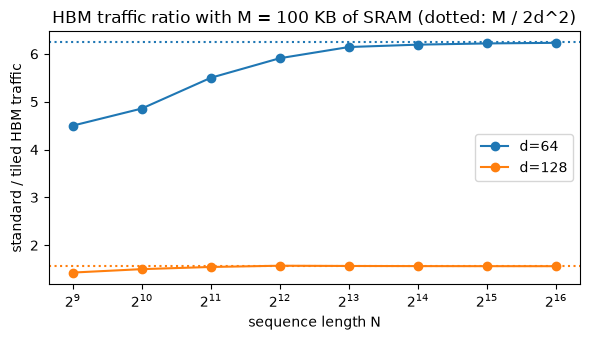

In [5]:
def hbm_elems_standard(N, d):
    return 4 * N * d + 4 * N * N


def hbm_elems_flash(N, d, M):
    B = M // (4 * d)
    return 2 * N * d + 2 * N * d * math.ceil(N / B)


check("standard count", hbm_elems_standard(1024, 64) == 4 * 1024 * 64 + 4 * 1024**2)
check("flash count", hbm_elems_flash(1024, 64, 4 * 64 * 128) == 2 * 1024 * 64 + 2 * 1024 * 64 * 8)
M_3090 = 100 * 1024 // 2  # 100 KB of shared memory per SM, in fp16 elements
Ns = [2**p for p in range(9, 17)]
plt.figure(figsize=(6, 3.5))
for d_ in (64, 128):
    plt.semilogx(Ns, [hbm_elems_standard(n, d_) / hbm_elems_flash(n, d_, M_3090) for n in Ns], "o-", label=f"d={d_}")
plt.axhline(M_3090 / (2 * 64**2), ls=":", color="C0"); plt.axhline(M_3090 / (2 * 128**2), ls=":", color="C1")
plt.xscale("log", base=2); plt.xlabel("sequence length N"); plt.ylabel("standard / tiled HBM traffic")
plt.title("HBM traffic ratio with M = 100 KB of SRAM (dotted: M / 2d^2)"); plt.legend(); plt.tight_layout(); plt.show()

The traffic ratio saturates at a modest factor ($\approx 6$ at $d=64$), yet FlashAttention is far faster and,
crucially, its **memory** is $O(Nd)$ instead of $O(N^2)$. Real unfused implementations also make more passes than our
count (separate scale, mask, softmax and dropout kernels each read and write $N^2$), and in a real kernel the
repeated K/V reads mostly hit the 6 MB L2, not DRAM. Dao et al. measured 40.3 GB vs 4.4 GB of HBM reads/writes for
GPT-2 medium attention (FA1 Fig. 2).

## 5. Measure: naive attention vs the flash backend as $T$ grows

**Exercise 5.1.** Predict the extra memory that the naive forward keeps alive for the backward: `naive_saved_bytes(B, H, T,
d, bytes_per_el)`. Autograd saves $Q, K$ for the first matmul (they already exist), nothing for the division by a
Python scalar, the softmax *output* $P$ (new: $BHT^2$), $P$ and $V$ for the second matmul (no new memory), and you
keep the output $O$ (new: $BHTd$). The flash backend keeps $O$ and $L$ ($BHT$ fp32).

T=  512  naive: kept     9.2 MiB  peak    33.2 MiB     2.1 ms   |   flash: kept    1.0 MiB  peak    8.1 MiB    1.0 ms
ok  naive kept-for-backward at T=512
T= 1024  naive: kept    35.0 MiB  peak   131.0 MiB     1.5 ms   |   flash: kept    2.1 MiB  peak   16.1 MiB    0.6 ms
ok  naive kept-for-backward at T=1024
T= 2048  naive: kept   136.0 MiB  peak   520.0 MiB     4.8 ms   |   flash: kept    4.1 MiB  peak   32.3 MiB    1.0 ms
ok  naive kept-for-backward at T=2048
T= 4096  naive: kept   536.0 MiB  peak  2072.0 MiB    19.4 ms   |   flash: kept    8.3 MiB  peak   64.5 MiB    2.7 ms
ok  naive kept-for-backward at T=4096


T= 8192  naive: kept  2128.0 MiB  peak  8272.0 MiB    77.8 ms   |   flash: kept   16.5 MiB  peak  129.0 MiB    8.5 ms
ok  naive kept-for-backward at T=8192


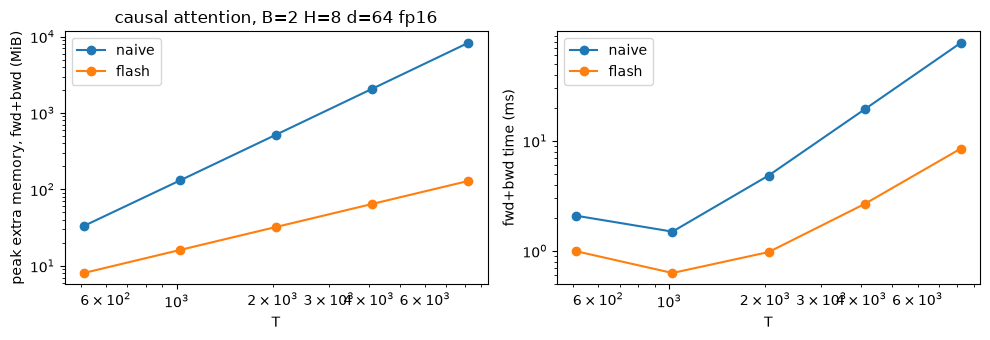

ok  naive peak memory grows ~4x per doubling of T at large T
ok  flash peak memory grows ~2x per doubling of T
at T=8192: naive needs 64x the memory of the flash backend


In [6]:
def naive_saved_bytes(B, H, T, d, bytes_per_el):
    return bytes_per_el * B * H * (T * T + T * d)


def naive_attention(q, k, v):
    T = q.shape[-2]
    S = (q @ k.transpose(-1, -2)) / math.sqrt(q.shape[-1])
    S = S.masked_fill(torch.ones(T, T, dtype=torch.bool, device=q.device).triu(1), float("-inf"))
    return S.softmax(-1) @ v


def flash_backend(q, k, v):
    with sdpa_kernel(SDPBackend.FLASH_ATTENTION):
        return F.scaled_dot_product_attention(q, k, v, is_causal=True)


def measure_attn(fn, B, H, T, d):
    q, k, v = (torch.randn(B, H, T, d, device=dev, dtype=torch.float16, requires_grad=True) for _ in range(3))
    dO = torch.randn_like(q)
    fn(q, k, v).backward(dO)  # warmup
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    m0 = torch.cuda.memory_allocated()
    t0 = time.perf_counter()
    o = fn(q, k, v)
    kept = torch.cuda.memory_allocated() - m0
    o.backward(dO)
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    return kept, torch.cuda.max_memory_allocated() - m0, dt


Bm, Hm, dm = 2, 8, 64
Ts = [512, 1024, 2048, 4096, 8192]
rows = {"naive": [], "flash": []}
for T in Ts:
    for name, fn in (("naive", naive_attention), ("flash", flash_backend)):
        rows[name].append(measure_attn(fn, Bm, Hm, T, dm))
    (kn, pn, tn), (kf, pf, tf) = rows["naive"][-1], rows["flash"][-1]
    print(f"T={T:5d}  naive: kept {kn / 2**20:7.1f} MiB  peak {pn / 2**20:7.1f} MiB  {tn * 1e3:6.1f} ms   |   "
          f"flash: kept {kf / 2**20:6.1f} MiB  peak {pf / 2**20:6.1f} MiB  {tf * 1e3:5.1f} ms")
    check_close(f"naive kept-for-backward at T={T}", kn, naive_saved_bytes(Bm, Hm, T, dm, 2), rtol=0.05, atol=0)

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for name in rows:
    axs[0].loglog(Ts, [r[1] / 2**20 for r in rows[name]], "o-", label=name)
    axs[1].loglog(Ts, [r[2] * 1e3 for r in rows[name]], "o-", label=name)
axs[0].set_xlabel("T"); axs[0].set_ylabel("peak extra memory, fwd+bwd (MiB)"); axs[0].legend()
axs[1].set_xlabel("T"); axs[1].set_ylabel("fwd+bwd time (ms)"); axs[1].legend()
axs[0].set_title(f"causal attention, B={Bm} H={Hm} d={dm} fp16"); plt.tight_layout(); plt.show()
ratio_mem = rows["naive"][-1][1] / rows["flash"][-1][1]
check("naive peak memory grows ~4x per doubling of T at large T", rows["naive"][-1][1] / rows["naive"][-2][1] > 3.0)
check("flash peak memory grows ~2x per doubling of T", rows["flash"][-1][1] / rows["flash"][-2][1] < 2.5)
print(f"at T={Ts[-1]}: naive needs {ratio_mem:.0f}x the memory of the flash backend")

## 6. What FlashAttention-2 and -3 changed

**FA2** (Dao 2023), same math, better use of the GPU:
1. *Fewer non-matmul FLOPs*: keep $\tilde O$ unnormalized and divide by $\ell$ once at the end; save only $L$ instead of
   $(m, \ell)$. On an A100, matmul throughput is 312 TFLOPS but non-matmul FP32 only 19.5, so each non-matmul FLOP is
   ~16× more expensive (FA2 §3.1).
2. *Parallelize over the sequence*: FA1 parallelized over batch × heads only; FA2 also splits the Q dimension across
   thread blocks (outer loop over Q tiles, as in our code), which fills the SMs at small batch and long context.
3. *Work partitioning between warps*: FA1 split K/V across the 4 warps of a block ("split-K"), so warps had to write
   partial results to shared memory and synchronize; FA2 splits Q across warps, and each warp owns its rows of the
   output (FA2 §3.3).
Result: 50-73% of peak on A100 forward, up to 225 TFLOPS/s per A100 in end-to-end GPT training (FA2 abstract).

**FA3** (Shah et al. 2024) targets Hopper (H100), so it cannot run on this sm_86 GPU. It exploits asynchronous
tensor cores (WGMMA) and the Tensor Memory Accelerator (TMA): **warp specialization** (producer warps issue TMA loads,
consumer warpgroups do matmuls), **ping-pong scheduling** so one warpgroup's softmax overlaps another's GEMMs, and
intra-warpgroup pipelining of softmax with the next tile's $QK^\top$. Its FP8 path uses block quantization and
"incoherent processing" (a random orthogonal Hadamard transform to spread outliers). Reported: 740 TFLOPS FP16 (75% of
H100 peak), close to 1.2 PFLOPS FP8, and 2.6× lower FP8 error than a baseline FP8 attention (FA3 abstract).

## Say it out loud
1. Derive the online softmax recurrence and prove $\ell_N$ is the correct normalizer. Why is the merge associative,
   and where is that used?
2. Write the FlashAttention forward loop for one Q tile from memory. What lives in SRAM, what goes to HBM?
3. Why does FlashAttention store $L$ and recompute $P$ in the backward instead of storing $P$? What is $D$ and why is
   it equal to $\mathrm{rowsum}(P\circ dP)$?
4. State the IO complexity of standard vs FlashAttention and the condition on $M$ and $d$. Is FlashAttention
   approximate? Does it reduce FLOPs?
5. How does causal masking change the tiled loop and the work?
6. Three things FA2 changed relative to FA1, and what FA3 adds on Hopper.
7. At decode time (one query, long KV cache) why is FlashAttention's "parallelize over Q tiles" useless, and what do
   you do instead?

<details><summary>Model answers</summary>

1. $m_j = \max(m_{j-1}, x_j)$, $\ell_j = \ell_{j-1}e^{m_{j-1}-m_j} + e^{x_j-m_j}$. Induction: if $\ell_{j-1} = \sum_{i<j} e^{x_i - m_{j-1}}$,
   multiplying by $e^{m_{j-1} - m_j}$ re-references every term to $m_j$, and adding the new term gives $\sum_{i\le j} e^{x_i - m_j}$
   (Milakov & Gimelshein 2018). The merge maps two (max, sum-of-exp) pairs to the pair of the union; it is the logsumexp
   of a union, which does not depend on grouping or order. Used across K/V tiles in FlashAttention, across thread blocks
   in split-KV decoding (flash-decoding), and across devices in ring/context-parallel attention.
2. Load $Q_i$; set $m=-\infty$, $\ell=0$, $\tilde O = 0$; for each K/V tile $j$: $S = Q_iK_j^\top/\sqrt d$, (mask), $m' = \max(m, \text{rowmax} S)$,
   $\tilde P = e^{S-m'}$, $\ell = e^{m-m'}\ell + \text{rowsum}\tilde P$, $\tilde O = e^{m-m'}\tilde O + \tilde P V_j$, $m = m'$; finally
   $O_i = \tilde O/\ell$, $L_i = m + \log\ell$. SRAM/registers: $Q_i$, the current $K_j, V_j$, $S$, $\tilde P$, $\tilde O$, $m$, $\ell$.
   HBM: $Q,K,V$ read, $O$ and $L$ written; never $S$ or $P$.
3. $P$ is $T^2$ per head: storing it is the $O(T^2)$ memory and traffic we are removing. Recomputing $S=QK^\top$ costs
   FLOPs, which are cheap on a GPU compared to HBM bytes. $L$ lets you rebuild normalized $P = e^{S-L}$ in one step, tile
   by tile. $D_i = \sum_j O_{ij}dO_{ij}$; since $O = PV$, $\sum_j P_{ij}dP_{ij} = (P\,dP^\top)_{ii} = (PV\,dO^\top)_{ii} = (O\,dO^\top)_{ii} = D_i$.
   This is what turns the softmax Jacobian-vector product $P\circ(dP - \mathrm{rowsum}(P\circ dP))$ into an elementwise op
   without a $T\times T$ reduction pass.
4. Standard $\Theta(Nd + N^2)$ HBM accesses, FlashAttention $\Theta(N^2d^2/M)$ for $d \le M \le Nd$ (Dao et al. Theorem 2), a
   big win when $d^2 \ll M$ (e.g. $d = 64$-128, $M\approx 100$ KB). It is exact (same result up to floating-point
   reassociation). It does not reduce FLOPs; it adds the recompute in the backward. The speedup comes from fewer bytes and
   from fusion, and the memory drops from $O(N^2)$ to $O(N)$ per head.
5. Skip all K/V tiles strictly above the diagonal (they contribute $e^{-\infty} = 0$), apply an elementwise mask only on
   diagonal tiles: roughly half the tiles and FLOPs. Rows of a tile that see no valid key yet need a guard (or a large
   negative constant like $-10^6$ instead of $-\infty$) to avoid $e^{-\infty-(-\infty)} = $ NaN.
6. FA2: fewer non-matmul FLOPs (late normalization, save only $L$), parallelism over the sequence (Q tiles across thread
   blocks), split-Q instead of split-K across warps (no shared-memory reduction). FA3 (Hopper): asynchronous WGMMA + TMA
   with warp-specialized producer/consumer warpgroups, ping-pong scheduling to overlap softmax with matmuls, and FP8 with
   block quantization and incoherent processing.
7. With one query there is one Q tile, so one thread block per (batch, head): far too few blocks to fill 82+ SMs, and
   each must stream the entire KV cache serially. Split the **KV** sequence across blocks instead (each computes partial
   $(m, \ell, \tilde O)$ for its chunk) and merge them with the associative rule: split-KV / flash-decoding. Decode
   attention is memory-bound anyway (each KV byte is used once per query), so the goal is to saturate bandwidth.
</details>

In [7]:
s.finish(lookups=0, score=None, notes="")

[G1.4] done in 0.0 min (within target 120 min)


0.040742305914560954